<a href="https://colab.research.google.com/github/RockStarz2912/LeetCode/blob/main/AnomalyScorePopulationComparisonandFutureDegradationEstimation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
# ============================================
# Predictive Maintenance Workflow (Integrated)
# ============================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# -----------------------------
# 1. Load Data
# -----------------------------
features = pd.read_csv("/content/sample_data/component_burn_screening_selected_features.csv")
normalized = pd.read_csv("/content/sample_data/component_burn_screening_normalized.csv")

# Drop non-numeric columns for modeling
X = normalized.drop(columns=["Device", "Transient_ID"])

In [22]:
# -----------------------------
# 2. Dimensionality Reduction
# -----------------------------
pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X)

In [23]:
# -----------------------------
# 3. Anomaly Detection
# -----------------------------
# EllipticEnvelope
detector = EllipticEnvelope(contamination=0.1, support_fraction=0.9, random_state=42)
detector.fit(X_pca)
scores_env = -detector.decision_function(X_pca)

# IsolationForest
iso = IsolationForest(contamination=0.1, random_state=42)
iso.fit(X_pca)
scores_iso = -iso.decision_function(X_pca)

# Attach raw scores
normalized["Anomaly_Score_Env"] = scores_env
normalized["Anomaly_Score_IF"] = scores_iso

In [24]:
# -----------------------------
# 4. Normalize Scores (0–1 range)
# -----------------------------
scaler = MinMaxScaler()
normalized["Anomaly_Score_Env_Pos"] = scaler.fit_transform(
    normalized[["Anomaly_Score_Env"]]
)
normalized["Anomaly_Score_IF_Pos"] = scaler.fit_transform(
    normalized[["Anomaly_Score_IF"]]
)

In [25]:
# -----------------------------
# 5. Population Comparison
# -----------------------------
pop_means = normalized.groupby("Device")[["Anomaly_Score_Env_Pos","Anomaly_Score_IF_Pos"]].mean()
print("\nPopulation Comparison (Normalized 0–1):\n", pop_means)


Population Comparison (Normalized 0–1):
               Anomaly_Score_Env_Pos  Anomaly_Score_IF_Pos
Device                                                   
Device2                    0.008455              0.185127
Device2b                   0.022583              0.214570
Device2check               0.966647              0.999220


In [26]:
# -----------------------------
# 6. Future Degradation Estimation
# -----------------------------
def forecast_degradation(df, device, score_col="Anomaly_Score_IF_Pos"):
    dev = df[df["Device"]==device].sort_values("Transient_ID")
    dev["RollingScore"] = dev[score_col].rolling(window=5, min_periods=1).mean()
    slope = np.polyfit(dev["Transient_ID"], dev["RollingScore"], 1)[0]
    forecast = dev["RollingScore"].iloc[-1] + slope*10  # next 10 transients
    return forecast

future_dev2 = forecast_degradation(normalized, "Device2")
future_dev2b = forecast_degradation(normalized, "Device2b")

print("\nFuture degradation estimate Device2:", future_dev2)
print("Future degradation estimate Device2b:", future_dev2b)


Future degradation estimate Device2: 0.34305935145877586
Future degradation estimate Device2b: 0.14443669562518274


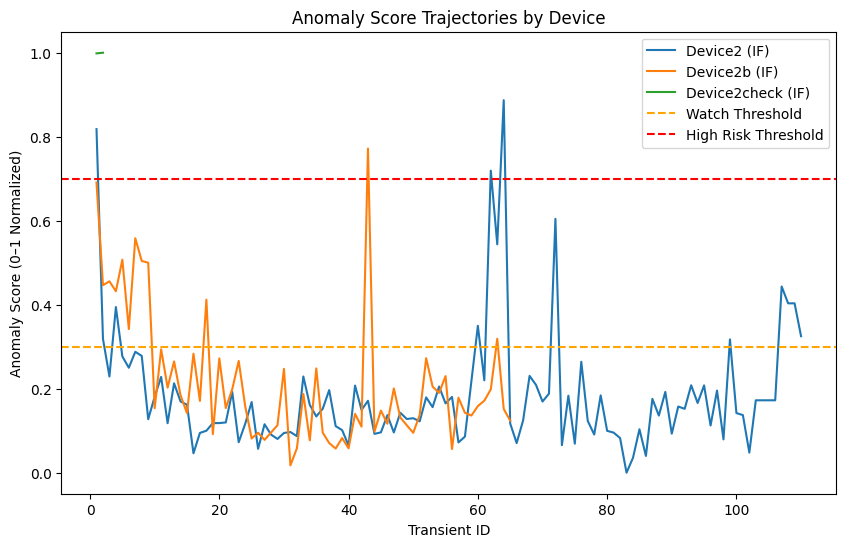

In [27]:
# -----------------------------
# 7. Visualization
# -----------------------------
plt.figure(figsize=(10,6))
for device in normalized["Device"].unique():
    subset = normalized[normalized["Device"]==device]
    plt.plot(subset["Transient_ID"], subset["Anomaly_Score_IF_Pos"], label=f"{device} (IF)")
plt.axhline(y=0.3, color='orange', linestyle='--', label="Watch Threshold")
plt.axhline(y=0.7, color='red', linestyle='--', label="High Risk Threshold")
plt.xlabel("Transient ID")
plt.ylabel("Anomaly Score (0–1 Normalized)")
plt.title("Anomaly Score Trajectories by Device")
plt.legend()
plt.show()